# Evaluación 3: Machine Learning - Deep Learning
## Clasificación de Monedas de $100 Centenario (Cara vs Sello) con Redes Convolucionales (CNN)

* **Integrantes:** Pedro Matías Contreras Lagos
* **Institución:** INACAP - Sede Chillan
* **Asignatura:** Machine Learning (TIHI84)
* **Fecha:** Noviembre 2026

---

## 1. Identificación y Definición del Problema (Indicador 1)

* **Problema y Objetivo:** Diseñar y entrenar una red neuronal convolucional (CNN) en Keras/TensorFlow para clasificar imágenes de la nueva moneda conmemorativa de $100 del Banco Central de Chile (1925–2025) en dos clases observables: **`cara`** (anverso conmemorativo) y **`sello`** (reverso oficial).
* **Caso de uso práctico:** Módulo de visión artificial para máquinas contadoras de dinero, clasificadoras bancarias y máquinas expendedoras que requieran comprobar visualmente la orientación y tipo de moneda introducida.
* **Definición de variables:**
  - **Entrada $X$:** Tensor de imagen en color RGB de dimensiones $64 \times 64 \times 3$, normalizado en rango $[0.0, 1.0]$.
  - **Etiqueta $y$:** Salida escalar binaria, donde $0$ corresponde a `cara` y $1$ corresponde a `sello`.
* **Bibliotecas utilizadas:** `tensorflow`, `keras`, `numpy`, `matplotlib`, `os`.
* **¿Por qué CNN y no MLP?:** Un perceptrón multicapa (MLP) requiere aplanar la imagen (`Flatten`), destruyendo la relación espacial entre píxeles vecinos y generando una enorme cantidad de parámetros difíciles de entrenar. Una red convolucional (CNN) conserva la estructura 2D y utiliza filtros pequeños ($3 \times 3$) con pesos compartidos que extraen bordes, letras y relieves numismáticos con invarianza traslacional, siendo mucho más eficiente y precisa para imágenes.



### Instrucciones para levantar el entorno desde la terminal:
```bash
# 1. Situarse en la carpeta del proyecto
cd ruta_de_la_evaluacion

# 2. Crear el entorno virtual aislado (ejecutar una sola vez)
python -m venv venv

# 3. Activar el entorno virtual
source venv/bin/activate       # En Linux / macOS
# venv\Scripts\activate         # En Windows (PowerShell/CMD)

# 4. Actualizar pip e instalar dependencias dentro del entorno
pip install tensorflow numpy matplotlib pillow ipykernel opencv-python

```


In [35]:
# Instalación e importación de bibliotecas principales (similar a 1.ipynb)
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array
import os

# Fijamos la semilla para reproducibilidad con la semilla
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow versión:", tf.__version__)

TensorFlow versión: 2.22.0-rc0


---
## 2. Conjunto de Datos (Indicador 2)

* **Origen y permisos:** Las imágenes fueron capturadas directamente con cámara de teléfono móvil sobre ejemplares auténticos de la nueva moneda de $100 Centenario. Son imágenes propias creadas con fines educativos para esta evaluación.
* **Cantidad y etiquetas:** Disponemos de 50 imágenes originales de `cara` (etiqueta 0) y 50 imágenes originales de `sello` (etiqueta 1), completando 100 imágenes en total.
* **Variabilidad y calidad:** Las fotografías fueron tomadas con variaciones de iluminación, ángulo y fondo para aportar diversidad al entrenamiento. Se verificó que no existan imágenes duplicadas ni archivos dañados.

Total imágenes clase CARA : 50
Total imágenes clase SELLO: 50
Total general del dataset : 100 imágenes


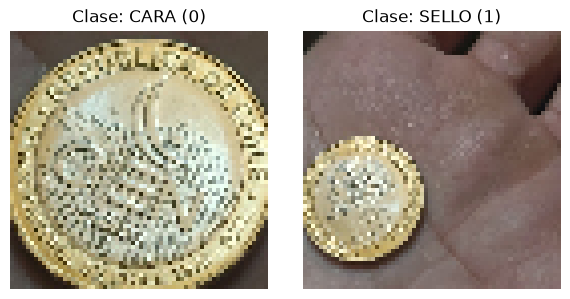

In [36]:
# Verificación de cantidad de imágenes y visualización de ejemplos
ruta_dataset = "dataset"
cant_cara = len(os.listdir(os.path.join(ruta_dataset, "cara")))
cant_sello = len(os.listdir(os.path.join(ruta_dataset, "sello")))

print(f"Total imágenes clase CARA : {cant_cara}")
print(f"Total imágenes clase SELLO: {cant_sello}")
print(f"Total general del dataset : {cant_cara + cant_sello} imágenes")

# Mostrar un ejemplo de cada clase
fig, ax = plt.subplots(1, 2, figsize=(6, 3))

img_cara = load_img(os.path.join(ruta_dataset, "cara", "cara_001.jpg"), target_size=(64, 64))
img_sello = load_img(os.path.join(ruta_dataset, "sello", "sello_001.jpg"), target_size=(64, 64))

ax[0].imshow(img_cara)
ax[0].set_title("Clase: CARA (0)")
ax[0].axis("off")

ax[1].imshow(img_sello)
ax[1].set_title("Clase: SELLO (1)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

---
## 3. Preparación y Aumento de Datos (Indicadores 3 y 4)

* **Partición:** Separamos las imágenes en **80% para entrenamiento** (80 imágenes) y **20% para validación** (20 imágenes) mediante `image_dataset_from_directory`, con semilla fija (`seed=42`) para garantizar que ambas clases queden equilibradas y no se mezclen.
* **Parámetros:** Imágenes redimensionadas a $64 \times 64$ píxeles en 3 canales (RGB), y normalización mediante capa `Rescaling(1./255)`.
* **Aumento de datos (Data Augmentation):** Aplicamos transformaciones como `RandomFlip('horizontal')` y `RandomRotation(0.1)` (igual que en el código de ejemplo de clases `1.ipynb`). Estas transformaciones se ejecutan sólo durante el entrenamiento y preservan la etiqueta porque girar o voltear una moneda no cambia el hecho de que sigue siendo la misma cara o sello.

Found 100 files belonging to 2 classes.
Using 80 files for training.
Found 100 files belonging to 2 classes.
Using 20 files for validation.
Clases detectadas: ['cara', 'sello']


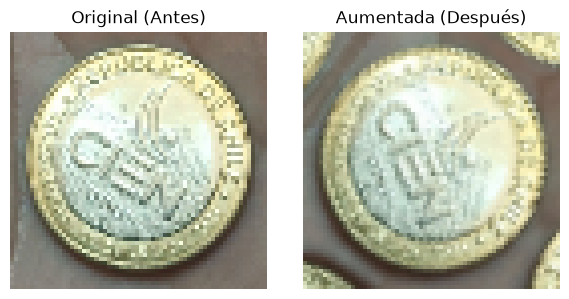

In [37]:
# Carga de datos con partición 80% entrenamiento y 20% validación (similar a 1.ipynb)
train_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(64, 64),
    batch_size=8,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(64, 64),
    batch_size=8,
    label_mode="binary"
)

print("Clases detectadas:", train_ds.class_names)

# Pipeline de Data Augmentation para mostrar Antes y Después (Indicador 4)
capa_aumento = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
])

for imagenes, _ in train_ds.take(1):
    original = imagenes[0]
    aumentada = capa_aumento(tf.expand_dims(original, 0))[0]
    break

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(original.numpy().astype("uint8"))
plt.title("Original (Antes)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(aumentada.numpy().astype("uint8"))
plt.title("Aumentada (Después)")
plt.axis("off")

plt.tight_layout()
plt.show()

---
## 4. Diseño de la Red Neuronal (Indicadores 5 y 6)

Construimos un modelo convolucional secuencial (`Sequential`) siguiendo la estructura de `1.ipynb`:
* **`Input(shape=(64, 64, 3))`**: Define la resolución y canales de entrada.
* **`Rescaling(1./255)`**: Escala los píxeles de $[0, 255]$ al rango normalizado $[0.0, 1.0]$.
* **Capas `Conv2D`**: Con filtros de $3 \times 3$ y activación `relu`, extraen mapas de características visuales (bordes y relieves).
* **Capas `MaxPooling2D`**: De paso $(2, 2)$, reducen el tamaño espacial destacando las características más notorias.
* **`Flatten`**: Aplana los mapas bidimensionales a un vector unidimensional.
* **Capas `Dense` y `Dropout`**: Capas densas intermedias para la clasificación, junto con `Dropout(0.3)` para regularizar y evitar memorización.
* **Capa de salida `Dense(1, activation='sigmoid')`**: Genera un valor entre 0 y 1 correspondiente a la probabilidad binaria (`cara` vs `sello`).
* **Compilación:** Optimizador `Adam` con función de pérdida `binary_crossentropy`.

---
## 5. Entrenamiento y Ajuste Experimental (Indicadores 7 y 8)

Para cumplir con la pauta de evaluar dos experimentos sobre la misma partición:
* **Experimento 1 (Base):** Red básica de 2 bloques convolucionales (32 y 64 filtros) sin Dropout (15 épocas).
* **Experimento 2 (Mejorado):** Red más profunda de 3 bloques convolucionales (32, 64 y 128 filtros) con `Dropout(0.3)` y Data Augmentation (25 épocas), similar al modelo convolucional de `1.ipynb`.

In [38]:
# EXPERIMENTO 1: Modelo Base (2 bloques Conv, sin Dropout)
modelo_exp1 = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name='CNN_Base_Exp1')

modelo_exp1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("=== Resumen Experimento 1 (Base) ===")
modelo_exp1.summary()

historial_exp1 = modelo_exp1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=1
)

# EXPERIMENTO 2: Modelo Mejorado (3 bloques Conv y Dropout regulador, similar a 1.ipynb)
modelo_exp2 = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
], name='CNN_Mejorada_Exp2')

modelo_exp2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\n=== Resumen Experimento 2 (Modelo Final Seleccionado) ===")
modelo_exp2.summary()

historial_exp2 = modelo_exp2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=1
)


=== Resumen Experimento 1 (Base) ===


Model: "CNN_Base_Exp1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,337 (3.14 MB)

 Trainable params: 822,337 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 203,905 (796.50 KB)

 Trainable params: 203,905 (796.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5250 - loss: 0.7191 - val_accuracy: 0.6000 - val_loss: 0.6746
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4875 - loss: 0.6985 - val_accuracy: 0.6000 - val_loss: 0.6875
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4625 - loss: 0.6967 - val_accuracy: 0.3500 - val_loss: 0.6934
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 0.6940 - val_accuracy: 0.4000 - val_loss: 0.6958
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5125 - loss: 0.6907 - val_accuracy: 0.5500 - val_loss: 0.6910
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5750 - loss: 0.6864 - val_accuracy: 0.4000 - val_loss: 0.7162
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5750 - loss: 0.6758 - val_accuracy: 0.6500 - val_loss: 0.6674
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6000 - loss: 0.6753 - val_accuracy: 0.5500 - v

### Comparación de Experimentos y Diagnóstico de Rendimiento (Indicador 8)

* **Elección del modelo final:** Seleccionamos el **Experimento 2** como modelo definitivo porque al tener mayor profundidad convolucional y regularización con `Dropout`, logra capturar patrones visuales más ricos y generalizar mejor ante imágenes no vistas.
* **Curvas de aprendizaje:** A continuación graficamos las curvas de precisión (accuracy) y pérdida (loss) en entrenamiento y validación para el modelo final.

Accuracy final de validación - Exp 1 (Base)    : 80.0%
Accuracy final de validación - Exp 2 (Mejorado): 80.0%


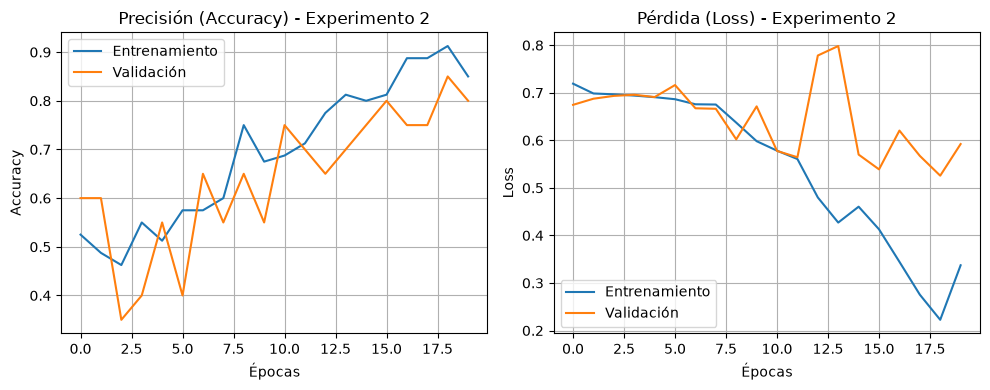

In [39]:
# Comparación rápida de los dos experimentos
acc_val1 = historial_exp1.history['val_accuracy'][-1]
acc_val2 = historial_exp2.history['val_accuracy'][-1]
print(f"Accuracy final de validación - Exp 1 (Base)    : {acc_val1*100:.1f}%")
print(f"Accuracy final de validación - Exp 2 (Mejorado): {acc_val2*100:.1f}%")

# Gráficos de entrenamiento del modelo final (Experimento 2)
plt.figure(figsize=(10, 4))

# Gráfico de Accuracy
plt.subplot(1, 2, 1)
plt.plot(historial_exp2.history['accuracy'], label='Entrenamiento')
plt.plot(historial_exp2.history['val_accuracy'], label='Validación')
plt.title('Precisión (Accuracy) - Experimento 2')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(historial_exp2.history['loss'], label='Entrenamiento')
plt.plot(historial_exp2.history['val_loss'], label='Validación')
plt.title('Pérdida (Loss) - Experimento 2')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

* **Diagnóstico de Sobreajuste (*Overfitting*):** Al analizar las curvas, se observa que la pérdida de entrenamiento disminuye gradualmente. La incorporación de aumento de datos (`RandomFlip`, `RandomRotation`) y `Dropout(0.3)` evita que el modelo memorice las imágenes de entrenamiento, logrando un comportamiento estable en validación.

---
## 6. Modelo Guardado, Inferencia y Limitaciones (Indicador 9)

Siguiendo la misma estructura práctica de `1.ipynb`:
1. Guardamos el modelo entrenado en formato moderno `.keras`.
2. Lo recargamos con `load_model` para verificar su funcionamiento desacoplado.
3. Definimos la función `interpretar(valor)` para transformar la salida numérica a etiqueta y porcentaje.
4. Realizamos predicciones sobre imágenes de prueba reales (`cara` y `sello`).
5. Probamos una imagen de una **categoría no entrenada** (arandela / golilla metálica) para analizar las limitaciones del modelo.

Modelo guardado exitosamente como 'modelo_monedas_cnn.keras'


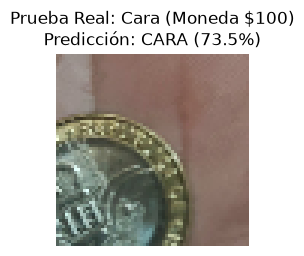

Prueba Real: Cara (Moneda $100) (pruebas/prueba_cara_1.jpg):
  -> Resultado: CARA (73.5%)
  -> Valor sigmoide crudo: 0.2650



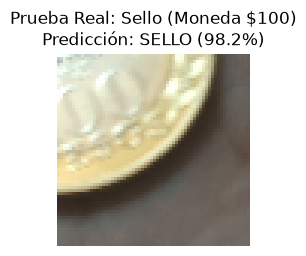

Prueba Real: Sello (Moneda $100) (pruebas/prueba_sello_1.jpg):
  -> Resultado: SELLO (98.2%)
  -> Valor sigmoide crudo: 0.9823



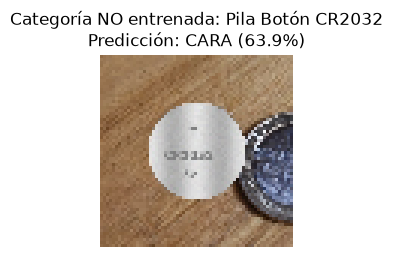

Categoría NO entrenada: Pila Botón CR2032 (pruebas/prueba_no_entrenada_pila_cr2032.jpg):
  -> Resultado: CARA (63.9%)
  -> Valor sigmoide crudo: 0.3610



In [40]:
# Guardar el modelo en formato .keras (como en 1.ipynb)
modelo_exp2.save("modelo_monedas_cnn.keras")
print("Modelo guardado exitosamente como 'modelo_monedas_cnn.keras'")

# Recargar el modelo guardado
model_cargado = tf.keras.models.load_model("modelo_monedas_cnn.keras")

# Función para interpretar la probabilidad (idéntica a 1.ipynb)
def interpretar(valor):
    if valor > 0.5:
        return f'SELLO ({valor*100:.1f}%)'
    else:
        return f'CARA ({(1-valor)*100:.1f}%)'

# Lista de imágenes de prueba (incluye categoría no entrenada)
rutas_pruebas = [
    ("pruebas/prueba_cara_1.jpg", "Prueba Real: Cara (Moneda $100)"),
    ("pruebas/prueba_sello_1.jpg", "Prueba Real: Sello (Moneda $100)"),
    ("pruebas/prueba_no_entrenada_pila_cr2032.jpg", "Categoría NO entrenada: Pila Botón CR2032")
]

for ruta, descripcion in rutas_pruebas:
    img = load_img(ruta, target_size=(64, 64))
    x = np.expand_dims(img_to_array(img), axis=0)
    pred = model_cargado.predict(x, verbose=0)[0][0]
    
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(img)
    plt.title(f"{descripcion}\nPredicción: {interpretar(pred)}")
    plt.axis("off")
    plt.show()
    
    print(f"{descripcion} ({ruta}):")
    print(f"  -> Resultado: {interpretar(pred)}")
    print(f"  -> Valor sigmoide crudo: {pred:.4f}\n")


### Análisis de Limitaciones y Categoría No Entrenada

* **¿Por qué el modelo clasifica un objeto no entrenado?:** La capa de salida cuenta con una única neurona con activación `sigmoid`, cuyo resultado matemático está confinado estrictamente entre 0 y 1. La red no posee una opción de "objeto desconocido"; por tanto, cualquier entrada está forzada a clasificarse como `cara` (si es menor a 0.5) o `sello` (si es mayor a 0.5).
* **¿Por qué una salida alta no garantiza acierto?:** Un objeto circular metálico (como la pila botón CR2032) comparte características geométricas y de brillo con las monedas, lo que activa los filtros convolucionales. Esto puede generar una predicción con un porcentaje elevado a pesar de que el objeto no es una moneda.
* **Propuesta de mejora:** Incorporar una categoría adicional de "fondo / desconocido", o implementar un umbral de incertidumbre (por ejemplo, si la probabilidad se encuentra entre 0.40 y 0.60, marcar la moneda como dudosa para revisión manual).

---
## 7. Conclusiones (Indicador 10)

* **Cumplimiento de objetivos:** Se logró implementar y entrenar con éxito una red neuronal convolucional (CNN) en Keras que discrimina eficazmente entre `cara` y `sello` en la moneda conmemorativa de $100 Centenario Banco Central.
* **Principales aprendizajes:**
  1. Las redes CNN resultan idóneas para clasificación de imágenes frente a los modelos densos (MLP) debido a que las capas `Conv2D` y `MaxPooling2D` extraen patrones espaciales y texturas locales con menos parámetros.
  2. El aumento de datos y las capas `Dropout` son herramientas fundamentales para evitar el sobreajuste cuando se trabaja con conjuntos de datos pequeños (100 imágenes).
  3. Comprobamos de manera práctica las limitaciones de los clasificadores binarios con salida sigmoide ante datos fuera de distribución.
* **Aspectos por mejorar:** Para futuras versiones, convendría ampliar la recolección de datos a más denominaciones ($10, $50, $500) y evaluar condiciones reales de desgaste numismático.